In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

In [2]:
# Load your prepared OpenAQ dataset
df = pd.read_csv("Nigdi_OpenAQ_Daily_Model_Ready.csv")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

df.head()

,date,no2,o3,pm10,pm25,humidity,temperature,wind_direction,wind_speed
0,2025-02-19,23.1,43.1,129.0,44.2,NaN,NaN,220.0,0.0684
1,2025-02-20,23.8,29.0,118.0,38.1,NaN,NaN,191.0,0.0704
2,2025-02-21,26.2,24.8,131.0,38.3,NaN,NaN,212.0,0.1580
3,2025-02-22,28.3,23.8,131.0,39.1,NaN,NaN,195.0,0.1390
4,2025-02-23,26.4,16.8,161.0,47.9,NaN,NaN,201.0,0.1130


In [5]:
import numpy as np

# Create time-based features
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.dayofweek

# Convert wind direction into circular features
df["wind_direction_sin"] = np.sin(np.radians(df["wind_direction"]))
df["wind_direction_cos"] = np.cos(np.radians(df["wind_direction"]))

# Create PM2.5 lag features
df["pm25_lag_1"] = df["pm25"].shift(1)
df["pm25_lag_3"] = df["pm25"].shift(3)
df["pm25_7day_avg"] = df["pm25"].rolling(window=7).mean()

# Predict the following day's PM2.5
df["pm25_next_day"] = df["pm25"].shift(-1)

# Avoid using a target if the following row is not actually the next calendar day
df["next_date"] = df["date"].shift(-1)
is_next_day = (df["next_date"] - df["date"]).dt.days == 1
df.loc[~is_next_day, "pm25_next_day"] = pd.NA

df.head()

,date,no2,o3,pm10,pm25,humidity,temperature,wind_direction,wind_speed,month,day_of_week,wind_direction_sin,wind_direction_cos,pm25_lag_1,pm25_lag_3,pm25_7day_avg,pm25_next_day,next_date
0,2025-02-19,23.1,43.1,129.0,44.2,NaN,NaN,220.0,0.0684,2,2,-0.642788,-0.766044,NaN,NaN,NaN,38.1,2025-02-20
1,2025-02-20,23.8,29.0,118.0,38.1,NaN,NaN,191.0,0.0704,2,3,-0.190809,-0.981627,44.2,NaN,NaN,38.3,2025-02-21
2,2025-02-21,26.2,24.8,131.0,38.3,NaN,NaN,212.0,0.1580,2,4,-0.529919,-0.848048,38.1,NaN,NaN,39.1,2025-02-22
3,2025-02-22,28.3,23.8,131.0,39.1,NaN,NaN,195.0,0.1390,2,5,-0.258819,-0.965926,38.3,44.2,NaN,47.9,2025-02-23
4,2025-02-23,26.4,16.8,161.0,47.9,NaN,NaN,201.0,0.1130,2,6,-0.358368,-0.933580,39.1,38.1,NaN,41.2,2025-02-24


In [6]:
# Choose input columns and target
features = [
    "pm25", "pm10", "no2", "o3",
    "temperature", "humidity",
    "wind_speed",
    "wind_direction_sin", "wind_direction_cos",
    "month", "day_of_week",
    "pm25_lag_1", "pm25_lag_3", "pm25_7day_avg"
]

target = "pm25_next_day"

# Remove rows where target is unavailable
model_df = df[features + [target, "date"]].dropna(subset=[target]).copy()

print("Rows available for modelling:", len(model_df))
model_df.head()

Rows available for modelling: 504


,pm25,pm10,no2,o3,temperature,humidity,wind_speed,wind_direction_sin,wind_direction_cos,month,day_of_week,pm25_lag_1,pm25_lag_3,pm25_7day_avg,pm25_next_day,date
0,44.2,129.0,23.1,43.1,NaN,NaN,0.0684,-0.642788,-0.766044,2,2,NaN,NaN,NaN,38.1,2025-02-19
1,38.1,118.0,23.8,29.0,NaN,NaN,0.0704,-0.190809,-0.981627,2,3,44.2,NaN,NaN,38.3,2025-02-20
2,38.3,131.0,26.2,24.8,NaN,NaN,0.1580,-0.529919,-0.848048,2,4,38.1,NaN,NaN,39.1,2025-02-21
3,39.1,131.0,28.3,23.8,NaN,NaN,0.1390,-0.258819,-0.965926,2,5,38.3,44.2,NaN,47.9,2025-02-22
4,47.9,161.0,26.4,16.8,NaN,NaN,0.1130,-0.358368,-0.933580,2,6,39.1,38.1,NaN,41.2,2025-02-23


In [7]:
# Time-based 80/20 split: older data trains the model; newer data tests it
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index]
test_df = model_df.iloc[split_index:]

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

Training rows: 403
Testing rows: 101


In [8]:
# Median filling is learned from training data only, preventing test-data leakage
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("random_forest", RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

In [14]:
# Evaluation

mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print(f"MAE:  {mae:.2f} µg/m³")
print(f"RMSE: {rmse:.2f} µg/m³")
print(f"R²:   {r2:.3f}")

# Baseline: predict tomorrow's PM2.5 as today's PM2.5
baseline_predictions = X_test["pm25"]

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = mean_squared_error(y_test, baseline_predictions) ** 0.5
baseline_r2 = r2_score(y_test, baseline_predictions)

print(f"Baseline MAE:  {baseline_mae:.2f} µg/m³")
print(f"Baseline RMSE: {baseline_rmse:.2f} µg/m³")
print(f"Baseline R²:   {baseline_r2:.3f}")

MAE:  3.50 µg/m³
RMSE: 4.66 µg/m³
R²:   -0.004
Baseline MAE:  2.86 µg/m³
Baseline RMSE: 4.09 µg/m³
Baseline R²:   0.226


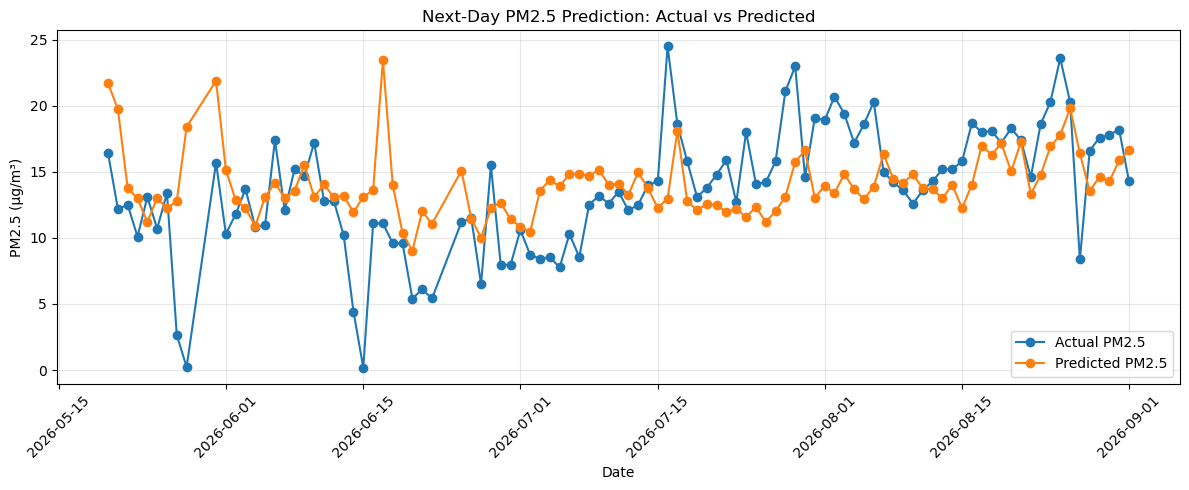

In [10]:
# Actual vs predicted chart
plt.figure(figsize=(12, 5))
plt.plot(test_df["date"], y_test.values, label="Actual PM2.5", marker="o")
plt.plot(test_df["date"], predictions, label="Predicted PM2.5", marker="o")
plt.title("Next-Day PM2.5 Prediction: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

               feature  importance
0                 pm25    0.707246
1                 pm10    0.114632
13       pm25_7day_avg    0.028800
12          pm25_lag_3    0.021253
2                  no2    0.020381
11          pm25_lag_1    0.018884
6           wind_speed    0.016087
3                   o3    0.014845
7   wind_direction_sin    0.013918
9                month    0.013097
8   wind_direction_cos    0.011514
10         day_of_week    0.008123
4          temperature    0.006029
5             humidity    0.005192


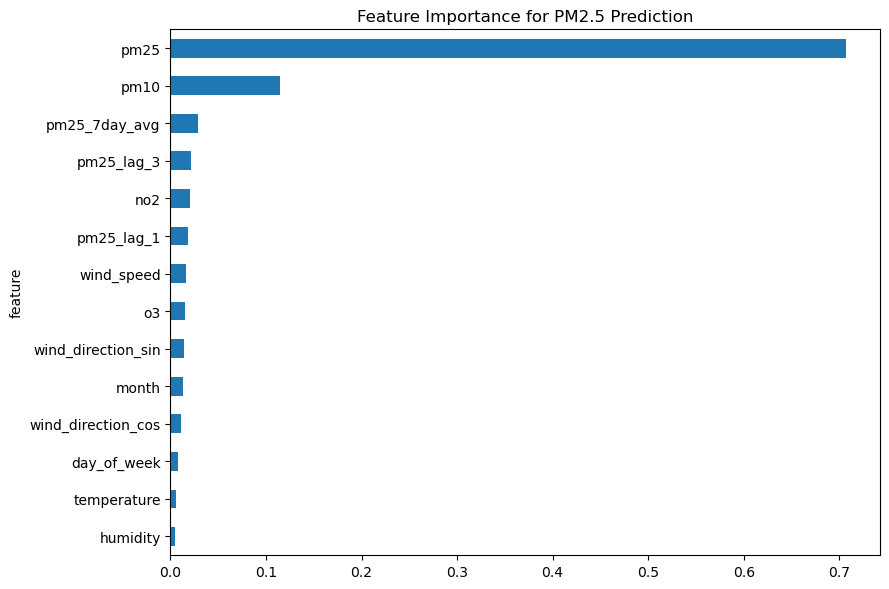

In [11]:
# Feature importance: helpful for your presentation/viva
importance = model.named_steps["random_forest"].feature_importances_

importance_df = (
    pd.DataFrame({"feature": features, "importance": importance})
    .sort_values("importance", ascending=False)
)

print(importance_df)

importance_df.plot(
    x="feature",
    y="importance",
    kind="barh",
    figsize=(9, 6),
    legend=False,
    title="Feature Importance for PM2.5 Prediction"
)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [12]:
# Save the trained model for later use
joblib.dump(model, "nigdi_pm25_random_forest_model.pkl")

['nigdi_pm25_random_forest_model.pkl']